Используемый CSV: /Users/lev/PycharmProjects/PAS_chargers/charged_ams_5_sites_2023-06-01_2023-09-30.csv

Данные загружены
Количество часов: 2928
Площадок: 5
Базовая мощность: 6.0 кВт
Резерв: 6.0 кВт

MAE по месяцам:
Июль: 0.4702 кВт·ч
Август: 0.6631 кВт·ч
Сентябрь: 0.3053 кВт·ч

Итог за август и сентябрь:
MAE = 0.4872 кВт·ч

MAE по площадкам:
Площадка 496: 0.5217
Площадка 1760: 0.5541
Площадка 254: 0.3722
Площадка 256: 0.3321
Площадка 1415: 0.6557


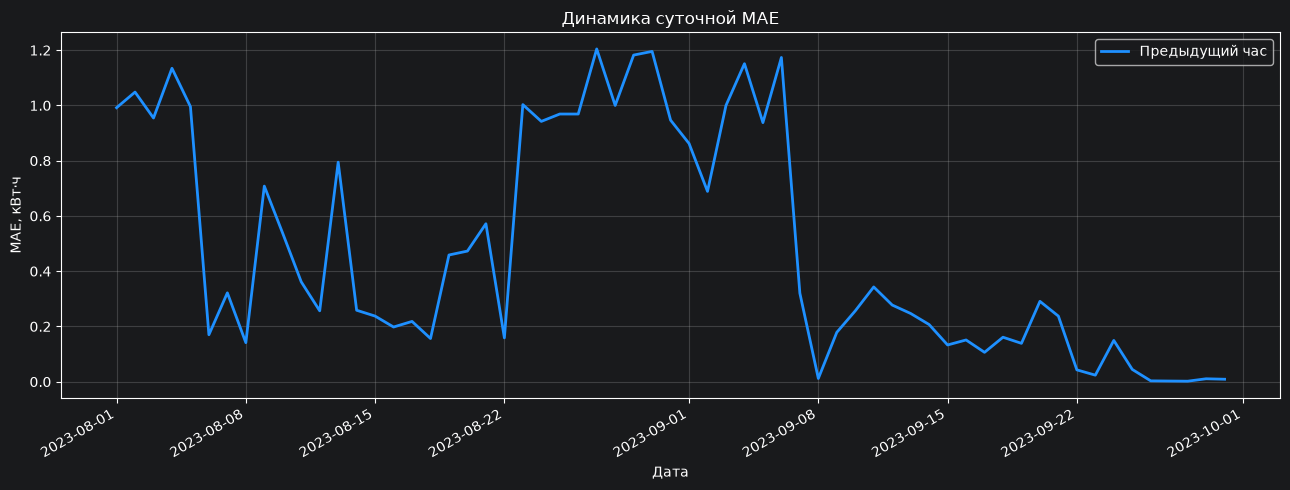

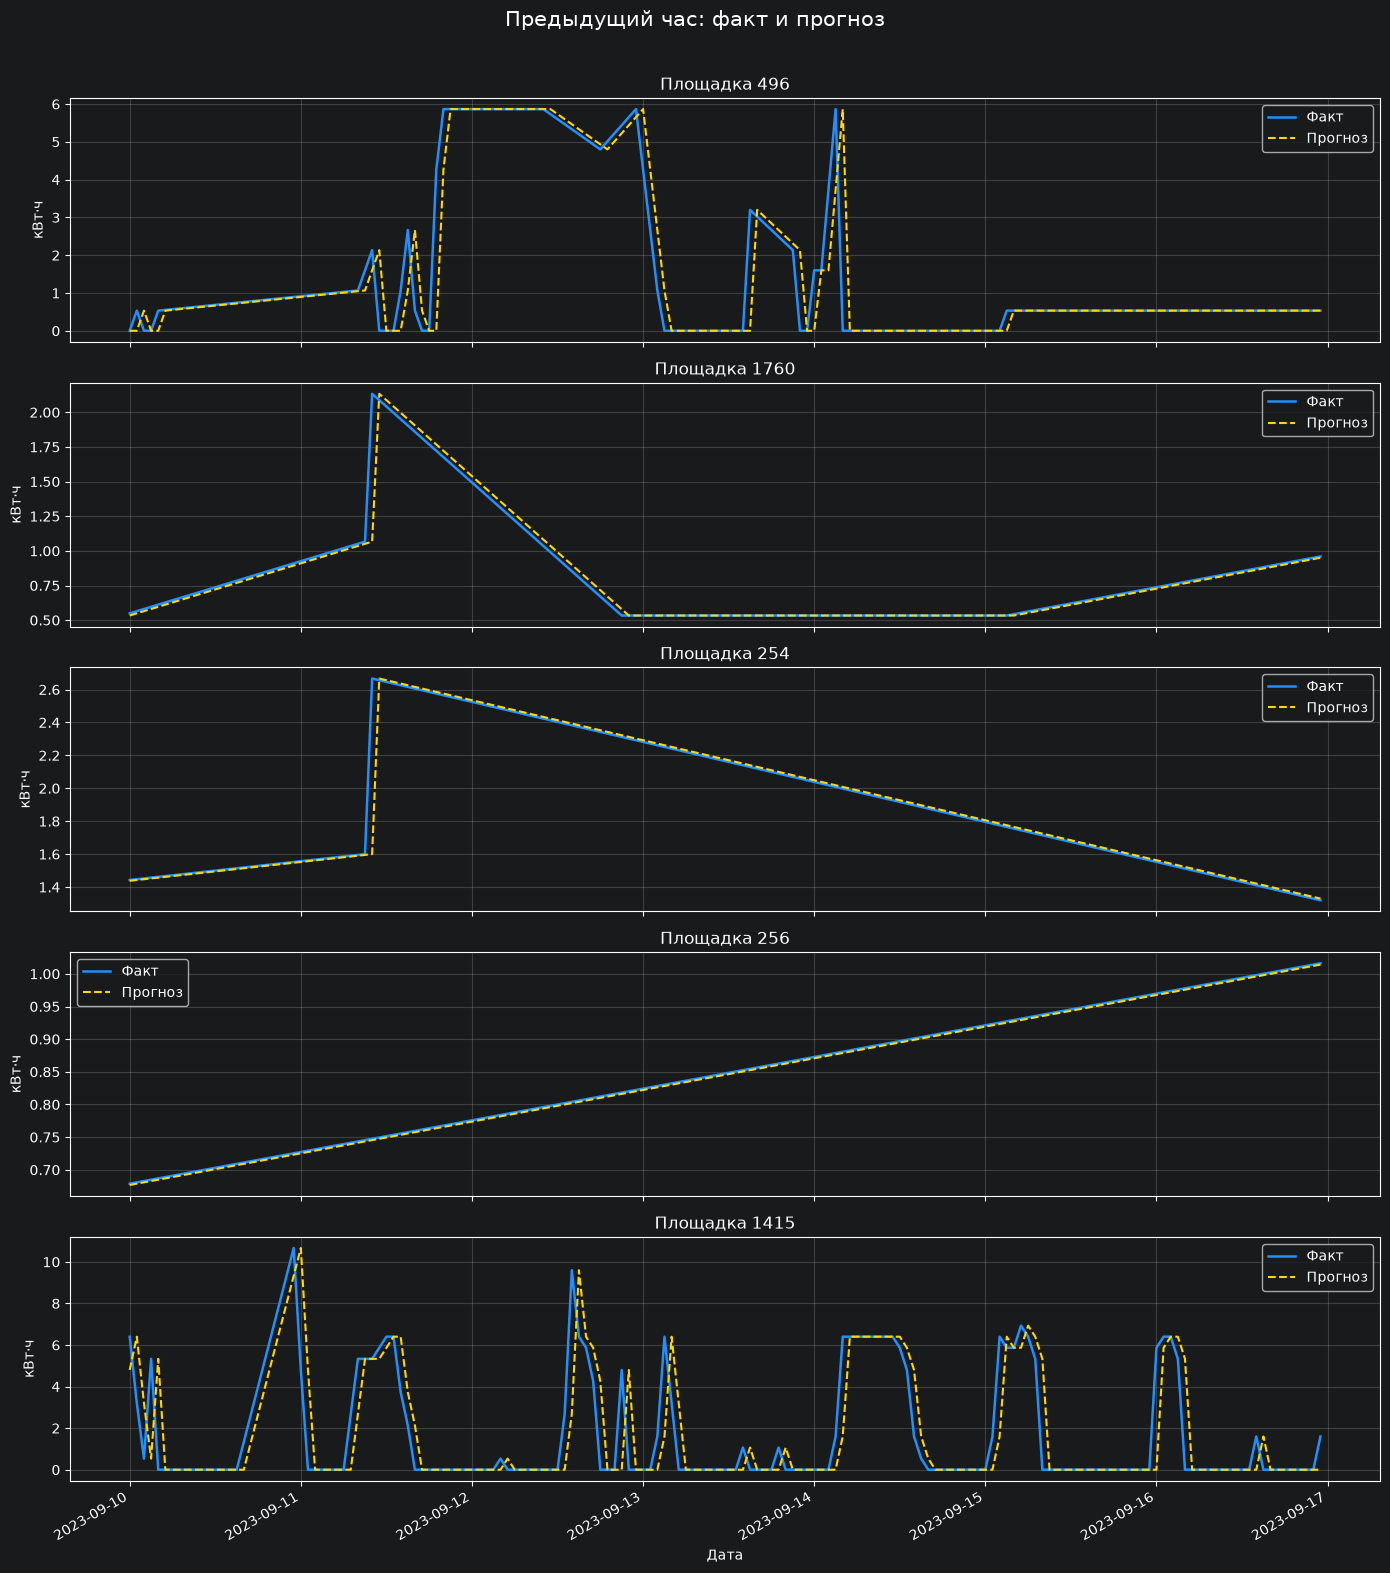

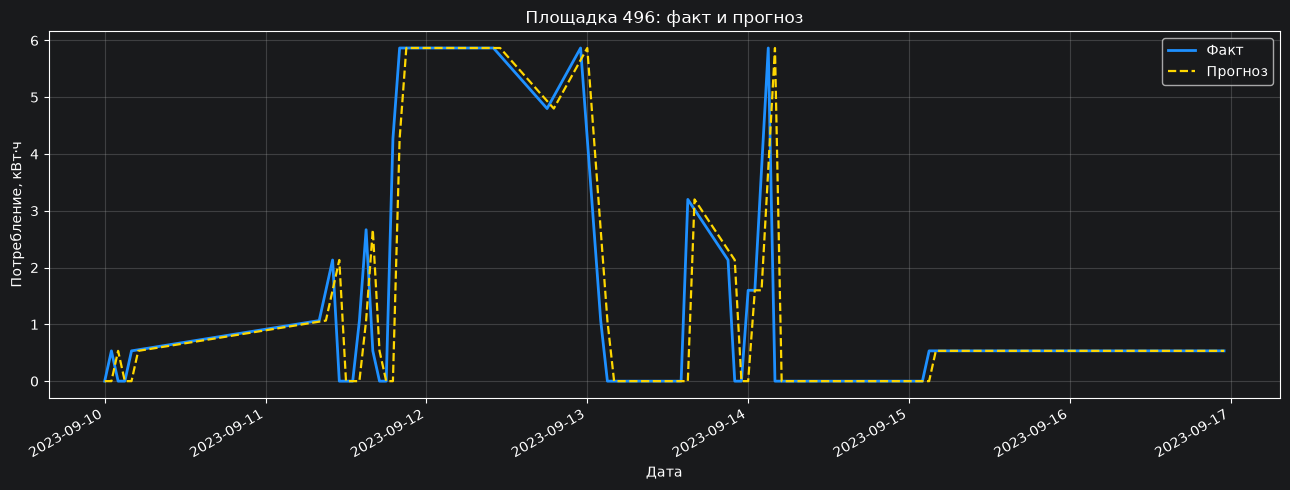

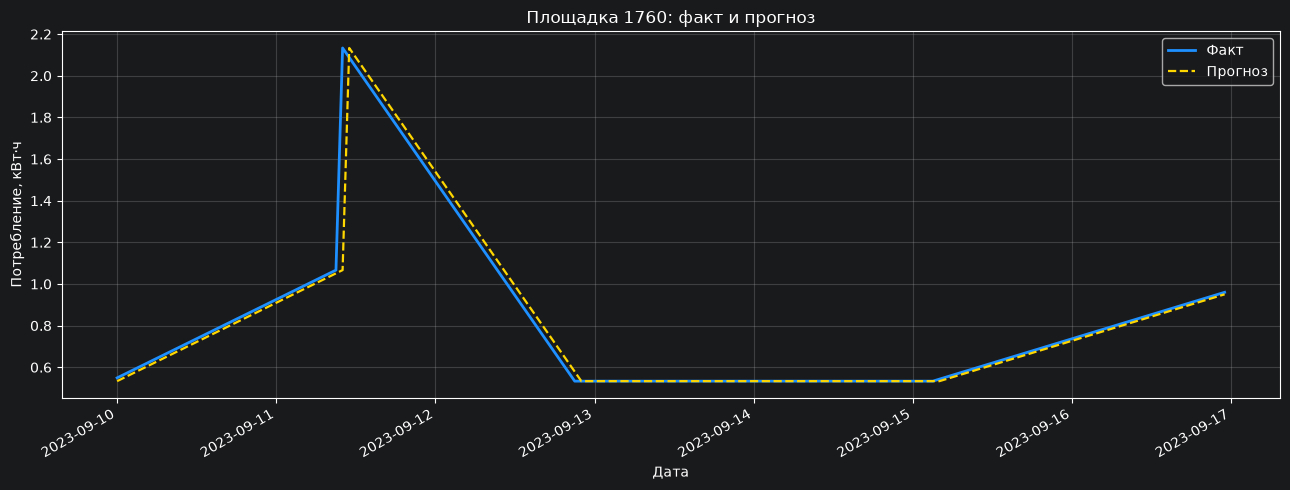

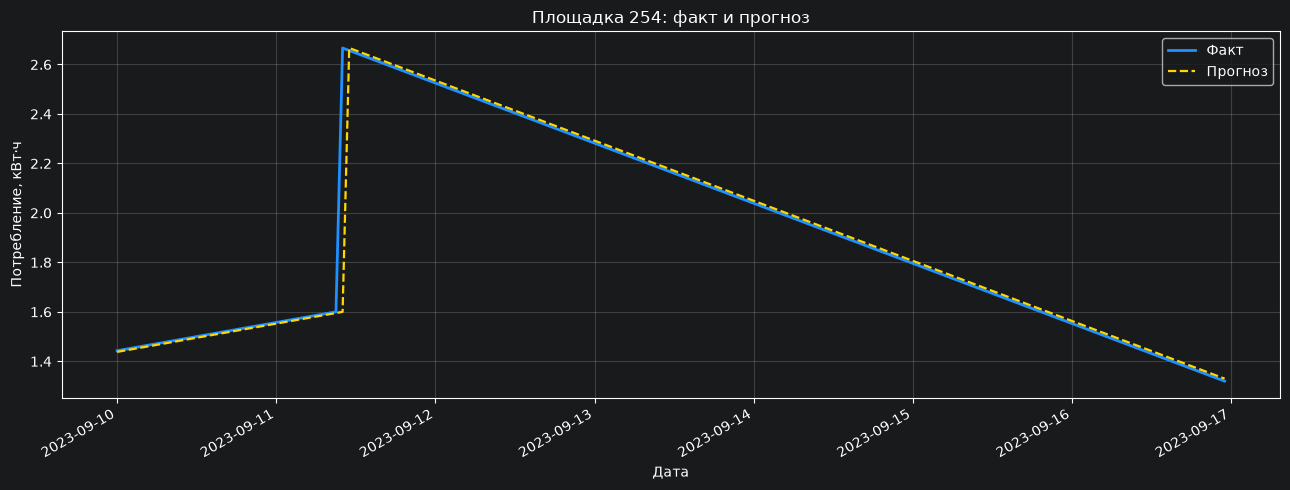

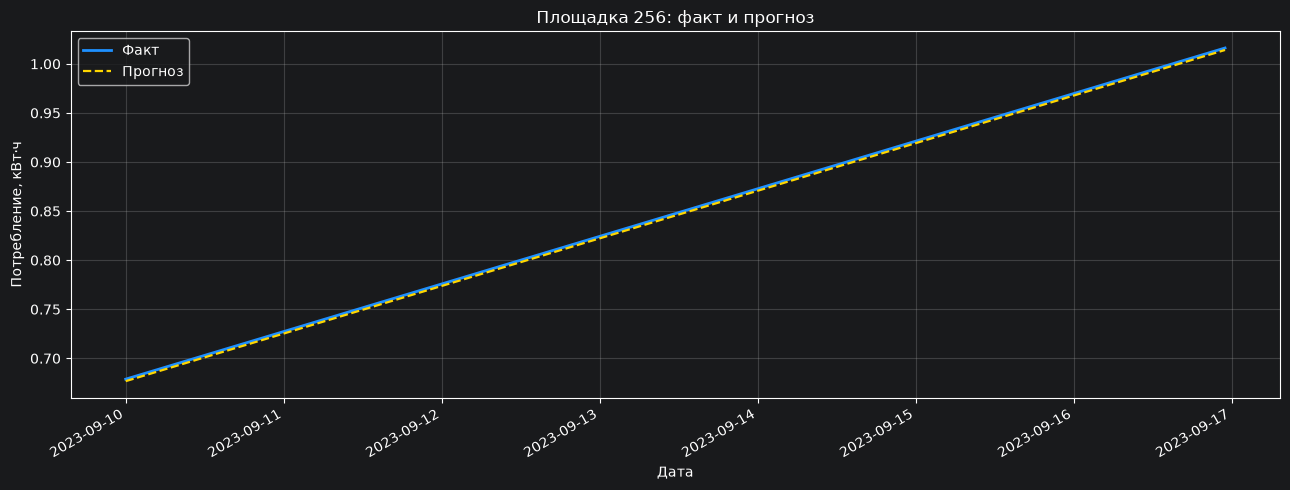

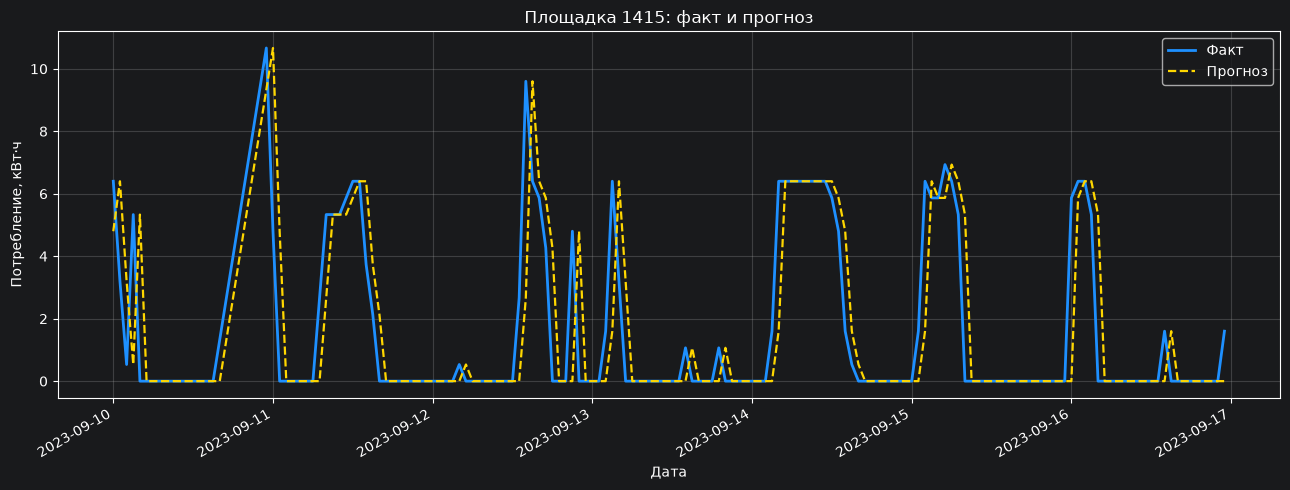


Проверка совпадения оптимизаторов:
Максимальное различие распределений: 0.0000000000 кВт

Результаты за август и сентябрь:
   optimizer  predicted_max_deficit_pct  actual_max_deficit_pct  oracle_max_deficit_pct  allocated_reserve_kw  unused_reserve_kw  unmet_energy_kwh
Equalization                     11.152                 25.4488                 11.1306                3.8457             2.1543            2.3626
          LP                     11.152                 25.4488                 11.1306                3.8457             2.1543            2.3626

Результаты по месяцам:
  month    optimizer  predicted_max_deficit_pct  actual_max_deficit_pct  oracle_max_deficit_pct  allocated_reserve_kw  unused_reserve_kw  unmet_energy_kwh
2023-08 Equalization                    19.9387                 38.4708                 19.8967                5.4708             0.5292            3.9490
2023-08           LP                    19.9387                 38.4708                 19.8967      

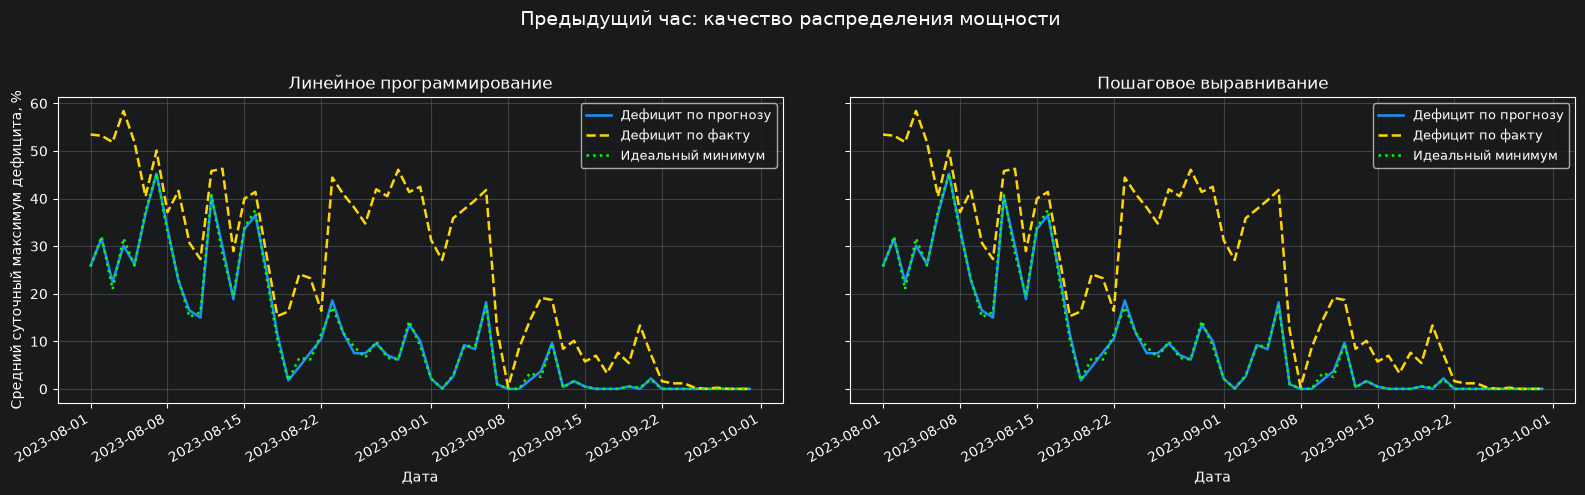


Время выполнения оптимизаторов:
 Оптимизатор  Среднее, мс  Медиана, мс  Суммарное время, мс  Число запусков
Equalization       0.0469       0.0288              68.6995            1464
          LP       0.9650       0.5700            1412.8024            1464

Среднее время одного распределения:
Equalization: 0.0469 мс
LP: 0.9650 мс

Все расчёты завершены.
Папка результатов: /Users/lev/PycharmProjects/PAS_chargers/previous_hour_results
Папка графиков: /Users/lev/PycharmProjects/PAS_chargers/previous_hour_results/figures


In [2]:

from pathlib import Path
from time import perf_counter_ns

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog


# Настройки

CSV_FILE = Path(
    "charged_ams_5_sites_2023-06-01_2023-09-30.csv"
)

SITES = ["496", "1760", "254", "256", "1415"]

BASE_POWER = np.array([1.0, 2.0, 1.0, 1.0, 1.0])
RESERVE_POWER = 6.0
INTERVAL_HOURS = 1.0

PLOT_START = "2023-09-10"
PLOT_END = "2023-09-17"

BASE_DIR = Path.cwd()

search_paths = [
    BASE_DIR / CSV_FILE,
    BASE_DIR.parent / CSV_FILE
]

if "__file__" in globals():
    search_paths.append(
        Path(__file__).resolve().parent / CSV_FILE
    )

CSV_PATH = next(
    (path for path in search_paths if path.is_file()),
    None
)

if CSV_PATH is None:
    checked = "\n".join(str(p) for p in search_paths)
    raise FileNotFoundError(
        f"CSV не найден.\n"
        f"Рабочая папка: {BASE_DIR}\n"
        f"Проверенные пути:\n{checked}"
    )

OUTPUT_DIR = BASE_DIR / "previous_hour_results"
FIGURES_DIR = OUTPUT_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Используемый CSV:", CSV_PATH.resolve())


# Единое оформление графиков


plt.rcParams.update({
    "figure.figsize": (12, 5),
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.facecolor": "#191a1c",
    "axes.facecolor": "#191a1c",
    "savefig.facecolor": "auto",
    "text.color": "white",
    "axes.labelcolor": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "axes.edgecolor": "white"
})

COLORS = {
    "actual": "dodgerblue",
    "predicted": "gold",
    "oracle": "lime"
}


def save_figure(fig, filename):
    fig.savefig(
        FIGURES_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )


# Загрузка данных

df = pd.read_csv(str(CSV_PATH))

df["time"] = pd.to_datetime(df["time"])
df = df.sort_values("time").reset_index(drop=True)

for site in SITES:
    df[site] = pd.to_numeric(
        df[site],
        errors="raise"
    )

expected_time = pd.date_range(
    "2023-06-01 00:00",
    "2023-09-30 23:00",
    freq="h"
)

if not pd.DatetimeIndex(df["time"]).equals(expected_time):
    raise ValueError("Временной ряд неполный")

if df[SITES].isna().any().any():
    raise ValueError("Есть пропущенные значения")

if (df[SITES] < 0).any().any():
    raise ValueError("Есть отрицательное потребление")

print("\nДанные загружены")
print("Количество часов:", len(df))
print("Площадок:", len(SITES))
print("Базовая мощность:", BASE_POWER.sum(), "кВт")
print("Резерв:", RESERVE_POWER, "кВт")


# Прогноз по предыдущему часу

pred = df[SITES].shift(1)

abs_error = (df[SITES] - pred).abs()

print("\nMAE по месяцам:")

for month, name in [
    (7, "Июль"),
    (8, "Август"),
    (9, "Сентябрь")
]:
    mask = df["time"].dt.month == month
    value = abs_error.loc[mask, SITES].to_numpy().mean()

    print(f"{name}: {value:.4f} кВт·ч")


# Итоговая проверочная выборка

test_mask = (
    (df["time"] >= "2023-08-01")
    & (df["time"] < "2023-10-01")
)

test_time = (
    df.loc[test_mask, "time"]
    .reset_index(drop=True)
)

actual_test = (
    df.loc[test_mask, SITES]
    .reset_index(drop=True)
)

pred_test = (
    pred.loc[test_mask, SITES]
    .reset_index(drop=True)
)

test_errors = (actual_test - pred_test).abs()

total_mae = test_errors.to_numpy().mean()

print("\nИтог за август и сентябрь:")
print(f"MAE = {total_mae:.4f} кВт·ч")

print("\nMAE по площадкам:")

for site in SITES:
    print(
        f"Площадка {site}: "
        f"{test_errors[site].mean():.4f}"
    )


# Сохранение прогнозов

prediction_frames = []

for site in SITES:
    frame = pd.DataFrame({
        "time": test_time,
        "site_id": int(site),
        "actual_kwh": actual_test[site],
        "predicted_kwh": pred_test[site],
        "absolute_error_kwh": test_errors[site]
    })

    prediction_frames.append(frame)

predictions_long = (
    pd.concat(prediction_frames, ignore_index=True)
    .sort_values(["time", "site_id"])
)

predictions_long.to_csv(
    OUTPUT_DIR / "predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


# Динамика суточной MAE

hourly_mae = test_errors.mean(axis=1)

daily_mae = pd.DataFrame({
    "time": test_time,
    "mae": hourly_mae
})

daily_mae = (
    daily_mae.set_index("time")
    .resample("D")
    .mean()
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    daily_mae.index,
    daily_mae["mae"],
    color=COLORS["actual"],
    linewidth=2,
    label="Предыдущий час"
)

ax.set_title("Динамика суточной MAE")
ax.set_xlabel("Дата")
ax.set_ylabel("MAE, кВт·ч")
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

save_figure(fig, "01_daily_mae.png")
plt.show()


# Графики прогноза по площадкам

plot_mask = (
    (df["time"] >= PLOT_START)
    & (df["time"] < PLOT_END)
)

plot_time = df.loc[plot_mask, "time"]

fig, axes = plt.subplots(
    5,
    1,
    figsize=(14, 16),
    sharex=True
)

for ax, site in zip(axes, SITES):
    ax.plot(
        plot_time,
        df.loc[plot_mask, site],
        color=COLORS["actual"],
        linewidth=1.8,
        label="Факт"
    )

    ax.plot(
        plot_time,
        pred.loc[plot_mask, site],
        color=COLORS["predicted"],
        linestyle="--",
        linewidth=1.5,
        label="Прогноз"
    )

    ax.set_title(f"Площадка {site}")
    ax.set_ylabel("кВт·ч")
    ax.legend()

axes[-1].set_xlabel("Дата")

fig.suptitle(
    "Предыдущий час: факт и прогноз",
    fontsize=15
)

fig.autofmt_xdate()
fig.tight_layout(rect=(0, 0, 1, 0.97))

save_figure(fig, "02_forecast_all_sites.png")
plt.show()


# Отдельные графики площадок

for site in SITES:
    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(
        plot_time,
        df.loc[plot_mask, site],
        color=COLORS["actual"],
        linewidth=2,
        label="Факт"
    )

    ax.plot(
        plot_time,
        pred.loc[plot_mask, site],
        color=COLORS["predicted"],
        linestyle="--",
        linewidth=1.6,
        label="Прогноз"
    )

    ax.set_title(f"Площадка {site}: факт и прогноз")
    ax.set_xlabel("Дата")
    ax.set_ylabel("Потребление, кВт·ч")
    ax.legend()

    fig.autofmt_xdate()
    fig.tight_layout()

    save_figure(fig, f"forecast_site_{site}.png")
    plt.show()


# Расчёт относительного дефицита

def relative_deficits(demand_kw, available_kw):
    demand = np.asarray(demand_kw, dtype=float)
    available = np.asarray(available_kw, dtype=float)

    shortage = np.maximum(
        demand - available,
        0.0
    )

    return np.divide(
        shortage,
        demand,
        out=np.zeros_like(demand),
        where=demand > 0
    )


def max_relative_deficit(demand_kw, reserve_kw):
    available = BASE_POWER + reserve_kw

    return float(
        relative_deficits(demand_kw, available).max()
    )


# Линейное программирование

def optimize_lp(predicted_kw):
    demand = np.maximum(
        np.asarray(predicted_kw, dtype=float),
        0.0
    )

    n = len(demand)

    objective = np.zeros(n + 1)
    objective[-1] = 1.0

    A_ub = np.zeros((n + 1, n + 1))
    b_ub = np.zeros(n + 1)

    for i in range(n):
        A_ub[i, i] = -1.0
        A_ub[i, -1] = -demand[i]
        b_ub[i] = BASE_POWER[i] - demand[i]

    A_ub[-1, :n] = 1.0
    b_ub[-1] = RESERVE_POWER

    bounds = (
        [(0.0, None)] * n
        + [(0.0, 1.0)]
    )

    solution = linprog(
        objective,
        A_ub=A_ub,
        b_ub=b_ub,
        bounds=bounds,
        method="highs"
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    z = float(np.clip(solution.x[-1], 0.0, 1.0))

    reserve = np.maximum(
        (1.0 - z) * demand - BASE_POWER,
        0.0
    )

    if reserve.sum() > RESERVE_POWER:
        reserve *= RESERVE_POWER / reserve.sum()

    return reserve


# Пошаговое выравнивание относительного дефицита

def optimize_equalization(predicted_kw):
    demand = np.maximum(
        np.asarray(predicted_kw, dtype=float),
        0.0
    )

    initial_deficits = relative_deficits(
        demand,
        BASE_POWER
    )

    levels = np.unique(
        initial_deficits[initial_deficits > 1e-12]
    )[::-1]

    reserve = np.zeros_like(demand)
    remaining = RESERVE_POWER

    for index, current_level in enumerate(levels):
        active = (
            initial_deficits >= current_level - 1e-12
        )

        next_level = (
            levels[index + 1]
            if index + 1 < len(levels)
            else 0.0
        )

        reduction = current_level - next_level

        required = (
            demand[active].sum() * reduction
        )

        if required <= remaining + 1e-10:
            reserve[active] += (
                demand[active] * reduction
            )

            remaining = max(
                0.0,
                remaining - required
            )

        else:
            total_demand = demand[active].sum()

            if total_demand > 0:
                reserve[active] += (
                    demand[active]
                    * remaining / total_demand
                )

            remaining = 0.0
            break

    return reserve


optimizers = {
    "LP": optimize_lp,
    "Equalization": optimize_equalization
}


# Предварительные вызовы для измерения времени

for index in range(min(10, len(test_time))):
    demand = (
        pred_test.iloc[index].to_numpy(dtype=float)
        / INTERVAL_HOURS
    )

    for optimizer_function in optimizers.values():
        optimizer_function(demand)


# Почасовая оптимизация

records = []
maximum_allocation_difference = 0.0

for index, time in enumerate(test_time):
    predicted_kwh = (
        pred_test.iloc[index].to_numpy(dtype=float)
    )

    actual_kwh = (
        actual_test.iloc[index].to_numpy(dtype=float)
    )

    predicted_kw = predicted_kwh / INTERVAL_HOURS
    actual_kw = actual_kwh / INTERVAL_HOURS

    oracle_reserve = optimize_equalization(actual_kw)

    oracle_deficit_pct = (
        100.0
        * max_relative_deficit(
            actual_kw,
            oracle_reserve
        )
    )

    allocations = {}

    for optimizer_name, optimizer_function in optimizers.items():
        start_ns = perf_counter_ns()

        reserve = optimizer_function(predicted_kw)

        elapsed_ms = (
            perf_counter_ns() - start_ns
        ) / 1_000_000

        allocations[optimizer_name] = reserve

        if reserve.sum() > RESERVE_POWER + 1e-7:
            raise RuntimeError(
                "Превышена доступная резервная мощность"
            )

        predicted_deficit_pct = (
            100.0
            * max_relative_deficit(
                predicted_kw,
                reserve
            )
        )

        actual_deficit_pct = (
            100.0
            * max_relative_deficit(
                actual_kw,
                reserve
            )
        )

        shortage_kw = np.maximum(
            actual_kw - BASE_POWER - reserve,
            0.0
        )

        allocated_kw = float(reserve.sum())
        unused_kw = max(
            0.0,
            RESERVE_POWER - allocated_kw
        )

        row = {
            "time": time,
            "optimizer": optimizer_name,
            "predicted_max_deficit_pct":
                predicted_deficit_pct,
            "actual_max_deficit_pct":
                actual_deficit_pct,
            "oracle_max_deficit_pct":
                oracle_deficit_pct,
            "allocated_reserve_kw":
                allocated_kw,
            "unused_reserve_kw":
                unused_kw,
            "unmet_energy_kwh":
                float(
                    shortage_kw.sum() * INTERVAL_HOURS
                ),
            "optimization_time_ms":
                elapsed_ms
        }

        for site_index, site in enumerate(SITES):
            row[f"reserve_{site}_kw"] = (
                reserve[site_index]
            )

            row[f"forecast_{site}_kwh"] = (
                predicted_kwh[site_index]
            )

            row[f"actual_{site}_kwh"] = (
                actual_kwh[site_index]
            )

        records.append(row)

    difference = np.max(
        np.abs(
            allocations["LP"]
            - allocations["Equalization"]
        )
    )

    maximum_allocation_difference = max(
        maximum_allocation_difference,
        float(difference)
    )

results = pd.DataFrame(records)

print("\nПроверка совпадения оптимизаторов:")
print(
    "Максимальное различие распределений:",
    f"{maximum_allocation_difference:.10f} кВт"
)

assert maximum_allocation_difference < 1e-6, (
    "LP и выравнивание дали разные распределения"
)


# Итоговые показатели

quality_columns = [
    "predicted_max_deficit_pct",
    "actual_max_deficit_pct",
    "oracle_max_deficit_pct",
    "allocated_reserve_kw",
    "unused_reserve_kw",
    "unmet_energy_kwh"
]

summary = (
    results.groupby("optimizer")[quality_columns]
    .mean()
    .reset_index()
)

print("\nРезультаты за август и сентябрь:")
print(summary.round(4).to_string(index=False))


# Таблица по месяцам

results["month"] = (
    results["time"].dt.strftime("%Y-%m")
)

monthly_summary = (
    results.groupby(
        ["month", "optimizer"]
    )[quality_columns]
    .mean()
    .reset_index()
)

print("\nРезультаты по месяцам:")
print(
    monthly_summary.round(4).to_string(index=False)
)


# Суточная динамика дефицита

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 5),
    sharey=True
)

for ax, optimizer_name in zip(
    axes,
    optimizers.keys()
):
    subset = (
        results.loc[
            results["optimizer"] == optimizer_name
        ]
        .set_index("time")
    )

    daily = subset.resample("D")[
        [
            "predicted_max_deficit_pct",
            "actual_max_deficit_pct",
            "oracle_max_deficit_pct"
        ]
    ].mean()

    ax.plot(
        daily.index,
        daily["predicted_max_deficit_pct"],
        color=COLORS["actual"],
        linewidth=1.8,
        label="Дефицит по прогнозу"
    )

    ax.plot(
        daily.index,
        daily["actual_max_deficit_pct"],
        color=COLORS["predicted"],
        linestyle="--",
        linewidth=1.8,
        label="Дефицит по факту"
    )

    ax.plot(
        daily.index,
        daily["oracle_max_deficit_pct"],
        color=COLORS["oracle"],
        linestyle=":",
        linewidth=1.8,
        label="Идеальный минимум"
    )

    name = (
        "Линейное программирование"
        if optimizer_name == "LP"
        else "Пошаговое выравнивание"
    )

    ax.set_title(name)
    ax.set_xlabel("Дата")
    ax.legend(fontsize=9)

axes[0].set_ylabel(
    "Средний суточный максимум дефицита, %"
)

fig.suptitle(
    "Предыдущий час: качество распределения мощности",
    fontsize=14
)

fig.autofmt_xdate()
fig.tight_layout(rect=(0, 0, 1, 0.95))

save_figure(fig, "03_daily_deficits.png")
plt.show()


# Время выполнения оптимизаторов


# Среднее время выполнения оптимизаторов

timing_summary = (
    results.groupby(["optimizer"])
    ["optimization_time_ms"]
    .agg(["mean", "median", "sum", "count"])
    .reset_index()
)

timing_summary.columns = [
    "Оптимизатор",
    "Среднее, мс",
    "Медиана, мс",
    "Суммарное время, мс",
    "Число запусков"
]

print("\nВремя выполнения оптимизаторов:")
print(timing_summary.round(4).to_string(index=False))

overall_timing = (
    results.groupby("optimizer")["optimization_time_ms"]
    .mean()
)

print("\nСреднее время одного распределения:")
for name, value in overall_timing.items():
    print(f"{name}: {value:.4f} мс")



# Сохранение результатов

daily_mae.to_csv(
    OUTPUT_DIR / "daily_mae.csv",
    encoding="utf-8-sig"
)

results.to_csv(
    OUTPUT_DIR / "hourly_recommendations.csv",
    index=False,
    encoding="utf-8-sig"
)

summary.to_csv(
    OUTPUT_DIR / "summary.csv",
    index=False,
    encoding="utf-8-sig"
)

monthly_summary.to_csv(
    OUTPUT_DIR / "monthly_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

timing_summary.to_csv(
    OUTPUT_DIR / "optimizer_timing.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nВсе расчёты завершены.")
print("Папка результатов:", OUTPUT_DIR)
print("Папка графиков:", FIGURES_DIR)
